# Datos Faltantes

In [65]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [67]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
385,0.023546,0.050680,-0.019140,0.049415,-0.063487,-0.061125,0.004460,-0.039493,-0.025953,-0.013504,219.0
300,0.016281,-0.044642,0.073552,-0.041235,-0.004321,-0.013527,-0.013948,-0.001116,0.042897,0.044485,275.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
42,-0.060003,0.050680,-0.010517,-0.014863,-0.049727,-0.023547,-0.058127,0.015858,-0.009919,-0.034215,61.0
311,0.096197,-0.044642,0.040140,-0.057313,0.045213,0.060690,-0.021311,0.036154,0.012551,0.023775,180.0
200,0.056239,-0.044642,-0.057941,-0.007977,0.052093,0.049103,0.056003,-0.021412,-0.028323,0.044485,158.0
271,0.038076,0.050680,0.008883,0.042529,-0.042848,-0.021042,-0.039719,-0.002592,-0.018114,0.007207,127.0
76,-0.030942,0.050680,0.028284,0.070072,-0.126781,-0.106845,-0.054446,-0.047981,-0.030748,0.015491,170.0


In [68]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

Solo hay valores faltantes en dos columnas, bmi y bp tienen 44 datos faltantes cada una, aproximadamente el 9.95% del total de 442 registros. Todas las demás columnas están completas y no tienen ningun valor faltante o sea 0.

In [69]:
# Contar valores faltantes y porcentaje por columna
faltantes = pd.DataFrame({
    'Valores Faltantes': data.isnull().sum(),
    'Porcentaje %': (data.isnull().mean() * 100).round(2)
})
faltantes

,Valores Faltantes,Porcentaje %
age,0,0.00
sex,0,0.00
bmi,44,9.95
bp,44,9.95
s1,0,0.00
s2,0,0.00
s3,0,0.00
s4,0,0.00
s5,0,0.00
s6,0,0.00


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

Se rellena los 44 valores faltantes de la columna bmi usando la media de los datos disponibles, que es aprox -0.000205. El resultado lo guardo en una copia de la tabla para conservar los datos originales con faltantes y poder compararlos en los siguientes ejercicios. Después de este paso la columna bmi queda con 0 valores faltantes.

In [70]:
# Copia para no perder los NaN originales del dataframe 'data'
data_simple = data.copy()

# Imputación simple con la media en la columna 'bmi'
imputer_mean = SimpleImputer(strategy='mean')
data_simple[['bmi']] = imputer_mean.fit_transform(data_simple[['bmi']])

print(f"Media imputada en 'bmi': {imputer_mean.statistics_[0]:.6f}")
print(f"Valores faltantes en 'bmi' después de imputar: {data_simple['bmi'].isnull().sum()}")

# Muestra de filas que tenían NaN originalmente en 'bmi'
nan_bmi_idx = data[data['bmi'].isnull()].index
pd.DataFrame({
    'bmi_original': data.loc[nan_bmi_idx, 'bmi'],
    'bmi_imputado_media': data_simple.loc[nan_bmi_idx, 'bmi']
}).head()

Media imputada en 'bmi': -0.000205
Valores faltantes en 'bmi' después de imputar: 0


,bmi_original,bmi_imputado_media
9,NaN,-0.000205
30,NaN,-0.000205
39,NaN,-0.000205
55,NaN,-0.000205
70,NaN,-0.000205


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

La diferencia principal es que la imputación simple rellena todos los espacios vacíos con exactamente el mismo número o sea la media de cada columna, mientras que KNNImputer calcula un valor distinto para cada caso usando el promedio de los 5 registros más parecidos. Al comparar las estadísticas, la imputación simple reduce más la desviación estándar, en bmi baja de 0.0470 a 0.0446 y en bp de 0.0480 a 0.0456, mientras que KNNImputer mantiene valores más cercanos a la variación y mediana originales o sea 0.0454 en bmi y 0.0463 en bp.

In [71]:
# Imputar también 'bp' con la media en data_simple para comparar ambas columnas
imputer_mean_bp = SimpleImputer(strategy='mean')
data_simple[['bp']] = imputer_mean_bp.fit_transform(data_simple[['bp']])

data_knn = data.copy()
knn_imputer = KNNImputer(n_neighbors=5)
feature_cols = [col for col in data.columns if col != 'target']
data_knn[feature_cols] = knn_imputer.fit_transform(data_knn[feature_cols])

# Comparación de las primeras filas donde 'bmi' era NaN
comparacion_filas_bmi = pd.DataFrame({
    'bmi_original': data.loc[nan_bmi_idx, 'bmi'],
    'bmi_simple (media)': data_simple.loc[nan_bmi_idx, 'bmi'],
    'bmi_knn (5 vecinos)': data_knn.loc[nan_bmi_idx, 'bmi']
})
display(comparacion_filas_bmi.head())

# Comparación de estadísticas descriptivas en 'bmi' y 'bp'
resumen_comparativo = pd.DataFrame({
    'Original (bmi)': data['bmi'].describe(),
    'SimpleImputer (bmi)': data_simple['bmi'].describe(),
    'KNNImputer (bmi)': data_knn['bmi'].describe(),
    'Original (bp)': data['bp'].describe(),
    'SimpleImputer (bp)': data_simple['bp'].describe(),
    'KNNImputer (bp)': data_knn['bp'].describe()
}).loc[['count', 'mean', 'std', 'min', '50%', 'max']]

display(resumen_comparativo)

,bmi_original,bmi_simple (media),bmi_knn (5 vecinos)
9,NaN,-0.000205,0.069456
30,NaN,-0.000205,-0.000601
39,NaN,-0.000205,0.028284
55,NaN,-0.000205,-0.027116
70,NaN,-0.000205,-0.031858


,Original (bmi),SimpleImputer (bmi),KNNImputer (bmi),Original (bp),SimpleImputer (bp),KNNImputer (bp)
count,398.000000,442.000000,442.000000,398.000000,442.000000,442.000000
mean,-0.000205,-0.000205,0.000351,0.000465,0.000465,0.000061
std,0.046989,0.044583,0.045381,0.048043,0.045583,0.046334
min,-0.089197,-0.089197,-0.089197,-0.112399,-0.112399,-0.112399
50%,-0.007284,-0.000817,-0.005128,-0.005670,0.000465,-0.005670
max,0.160855,0.160855,0.160855,0.132044,0.132044,0.132044


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

En las gráficas se ve que al usar la imputación simple por media aparece un pico muy alto en el centro (como de de 0), porque los 44 datos faltantes se concentraron en un solo punto. En cambio, con KNNImputer los valores rellenados se reparten de manera más como natural a lo largo de la gráfica, conservando una forma muy parecida a la distribución original de bmi.

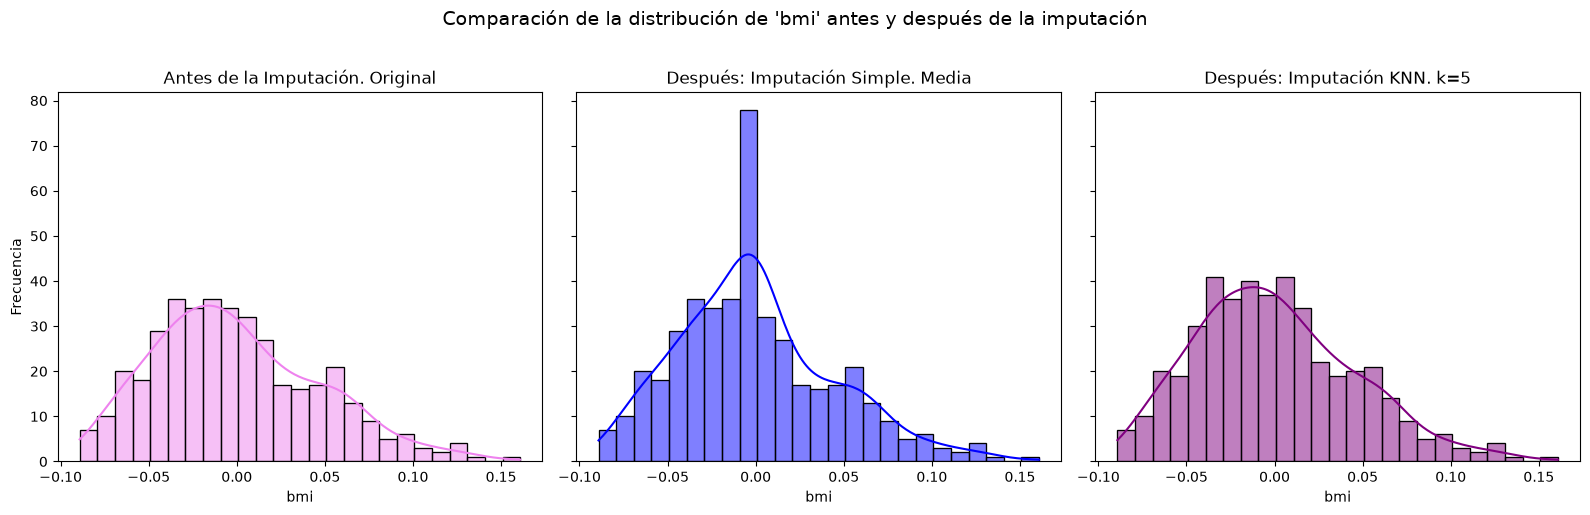

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

# Antes de la imputación o sea original
sns.histplot(data['bmi'].dropna(), bins=25, kde=True, color='violet', ax=axes[0])
axes[0].set_title("Antes de la Imputación. Original")
axes[0].set_xlabel("bmi")
axes[0].set_ylabel("Frecuencia")

# Después de imputación simple o sea media
sns.histplot(data_simple['bmi'], bins=25, kde=True, color='blue', ax=axes[1])
axes[1].set_title("Después: Imputación Simple. Media")
axes[1].set_xlabel("bmi")

# Después de Imputación KNN
sns.histplot(data_knn['bmi'], bins=25, kde=True, color='purple', ax=axes[2])
axes[2].set_title("Después: Imputación KNN. k=5")
axes[2].set_xlabel("bmi")

plt.suptitle("Comparación de la distribución de 'bmi' antes y después de la imputación", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()